# PC2 – PCA for the MNIST digit data

**Goal:** apply PCA to images of handwritten digits, find out how many dimensions are needed and check whether the 10 digits
can be separated in a 2-D PCA plot.

**Data source:** MNIST (70 000 images, 28 × 28 pixels) from OpenML, downloaded with `sklearn.datasets.fetch_openml`.
The first run downloads about 50 MB into `../data/sklearn_cache`; later runs use the cached copy.

As suggested in the exercise, we use a **random subset of 10 000 images** so that the computations run in a few seconds.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

X_all, y_all = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False,
                            data_home="../data/sklearn_cache", parser="liac-arff")
y_all = y_all.astype(int)
print("full data:", X_all.shape)

rng = np.random.default_rng(42)                      # fixed seed -> reproducible subset
idx = rng.choice(len(X_all), size=10_000, replace=False)
X, y = X_all[idx], y_all[idx]
print("subset   :", X.shape)

full data: (70000, 784)


subset   : (10000, 784)


## (a) Data understanding

In [2]:
print("value range:", X.min(), "to", X.max())
print("data type of the values:", X.dtype, "| all integers:", np.all(X == X.round()))
print("share of pixels that are exactly 0 (black):", round((X == 0).mean(), 3))
print("pixels that are 0 in every image of the subset:", int((X.std(axis=0) == 0).sum()), "of", X.shape[1])
print("\nnumber of images per digit:")
print(pd.Series(y).value_counts().sort_index().to_string())

value range: 0.0 to 255.0


data type of the values: float64 | all integers: True
share of pixels that are exactly 0 (black): 0.808


pixels that are 0 in every image of the subset: 112 of 784

number of images per digit:
0    1037
1    1117
2     987
3    1059
4     996
5     906
6     966
7    1062
8     949
9     921


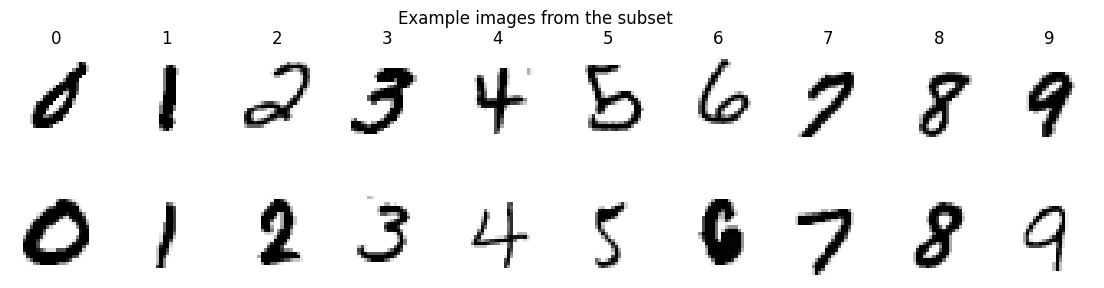

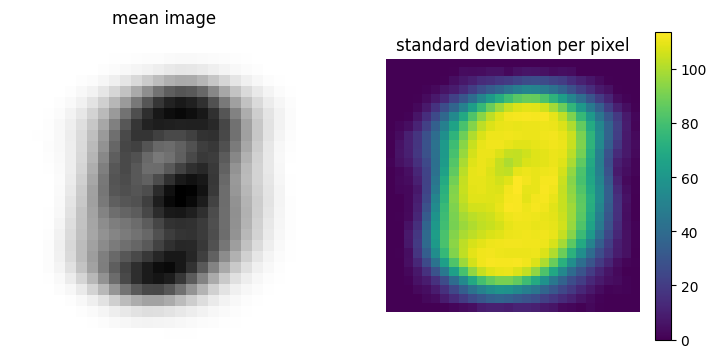

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(14, 3.2))
for d in range(10):
    for r in range(2):
        img = X[y == d][r].reshape(28, 28)
        axes[r, d].imshow(img, cmap="gray_r")
        axes[r, d].axis("off")
    axes[0, d].set_title(str(d))
plt.suptitle("Example images from the subset")
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(X.mean(axis=0).reshape(28, 28), cmap="gray_r"); ax[0].set_title("mean image")
im = ax[1].imshow(X.std(axis=0).reshape(28, 28), cmap="viridis"); ax[1].set_title("standard deviation per pixel")
fig.colorbar(im, ax=ax[1])
for a in ax: a.axis("off")
plt.show()

**What do we have?**
- **Rows:** images of handwritten digits (70 000 in total, we use 10 000). The label `y` (0 – 9) says which digit it is;
  the classes are roughly balanced (about 1000 images each).
- **Columns:** 784 = 28 × 28 pixels. Each image is "flattened" into one row; column *k* is the pixel at position
  (row *k* // 28, column *k* % 28).
- **Entries:** gray values, integers from **0 (background) to 255 (full ink)**. About 81 % of all values are 0, and 112 pixels
  at the border are 0 in every image (no variance at all).

**Should we normalize?**
**No standardization (z-scores).** All variables have the **same meaning (gray value of a pixel) and the same range 0 – 255**
(see lecture VO03, slide 11). Standardizing would even be harmful:
- Border pixels that are almost always 0 have a tiny standard deviation. Dividing by it would blow up rare noise into large values
  and give these unimportant pixels the same weight as the central pixels that carry the shape of the digit.
- Pixels with zero variance would cause a division by 0.

We only **scale to [0, 1]** by dividing by 255. This is the same factor for all pixels, so it does not change the PCA result
(only the units of the eigenvalues). PCA itself removes the mean (centering) automatically.

In [4]:
X = X / 255.0

## (b) Calculate the PCA and assess the number of needed dimensions

We compute all 784 components and look at the explained variance.

In [5]:
pca = PCA()
pca.fit(X)
ratio = pca.explained_variance_ratio_
cum = np.cumsum(ratio)

print("explained variance of the first 10 PCs:", ratio[:10].round(3))
print(f"PC1 + PC2 together explain: {cum[1]:.1%}\n")
for t in [0.5, 0.8, 0.9, 0.95, 0.99]:
    print(f"{t:.0%} of the variance needs {np.argmax(cum >= t) + 1:4d} components")

explained variance of the first 10 PCs: [0.1   0.071 0.061 0.053 0.049 0.043 0.033 0.029 0.028 0.024]
PC1 + PC2 together explain: 17.1%

50% of the variance needs   11 components
80% of the variance needs   43 components
90% of the variance needs   86 components
95% of the variance needs  151 components
99% of the variance needs  326 components


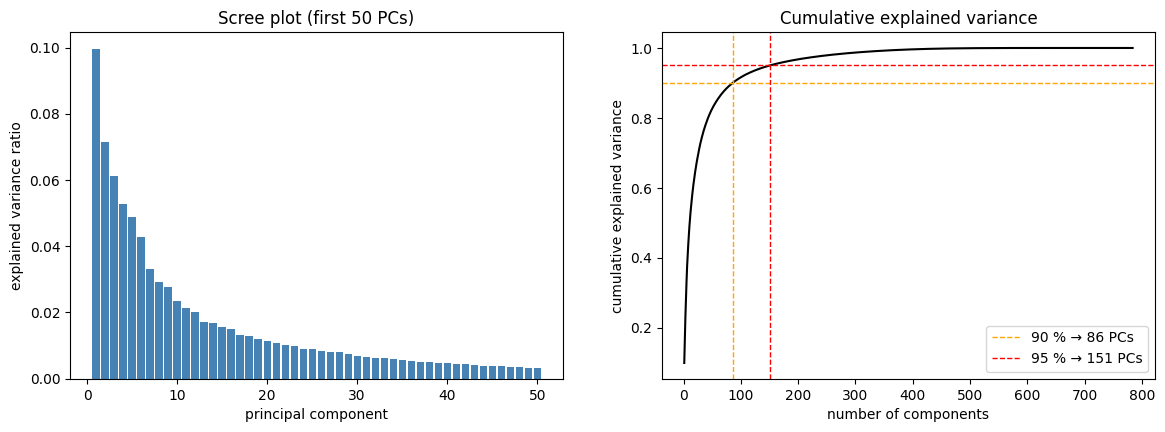

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].bar(np.arange(1, 51), ratio[:50], color="steelblue")
ax[0].set_xlabel("principal component"); ax[0].set_ylabel("explained variance ratio")
ax[0].set_title("Scree plot (first 50 PCs)")

ax[1].plot(np.arange(1, len(cum) + 1), cum, "k-")
for t, c in [(0.9, "orange"), (0.95, "red")]:
    k = np.argmax(cum >= t) + 1
    ax[1].axhline(t, color=c, ls="--", lw=1)
    ax[1].axvline(k, color=c, ls="--", lw=1, label=f"{int(t*100)} % → {k} PCs")
ax[1].set_xlabel("number of components"); ax[1].set_ylabel("cumulative explained variance")
ax[1].set_title("Cumulative explained variance"); ax[1].legend()
plt.show()

**Assessment:**
- The first PCs explain only small shares: PC1 ≈ 10 %, PC2 ≈ 7 %. **Together only ≈ 17 %**.
- For **90 %** we need **≈ 86** components, for **95 % ≈ 151** components (out of 784).
- So we can reduce the dimension by a factor of about **5 – 9** without losing much information – a big reduction, because
  neighbouring pixels are strongly correlated and many border pixels are always 0.
- But **2 or 3 dimensions are far from enough**: they keep less than a fifth of the information.

### What do the principal components look like?
Each PC is a vector of 784 numbers, so we can show it as an image ("eigen-digits"). Red = positive, blue = negative weight.

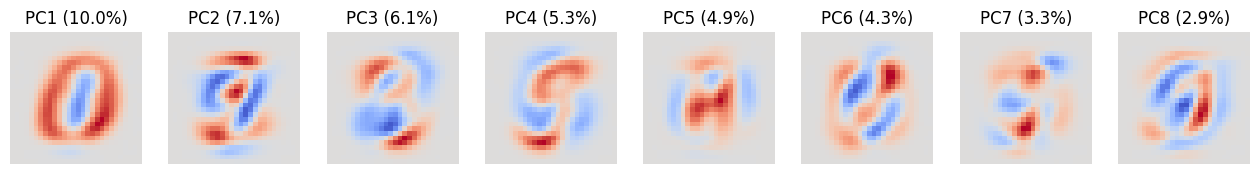

In [7]:
fig, axes = plt.subplots(1, 8, figsize=(16, 2.6))
for k, a in enumerate(axes):
    comp = pca.components_[k].reshape(28, 28)
    m = np.abs(comp).max()
    a.imshow(comp, cmap="coolwarm", vmin=-m, vmax=m)
    a.set_title(f"PC{k+1} ({ratio[k]:.1%})"); a.axis("off")
plt.show()

We can also see the information loss directly: reconstruct images from only the first *k* PCs and compare.

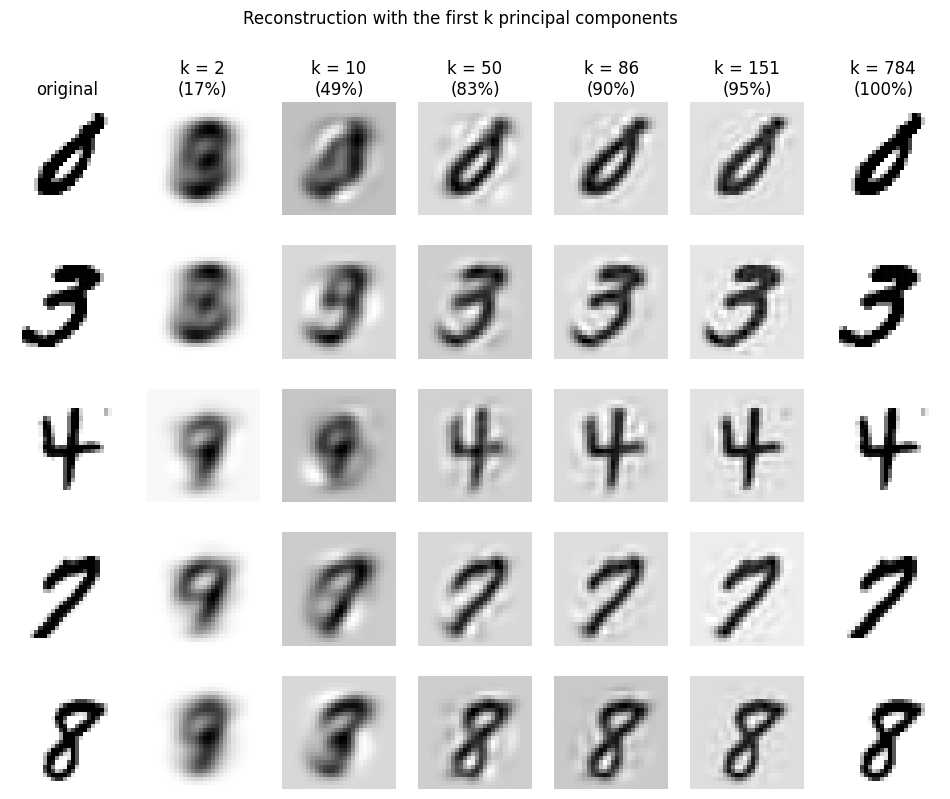

In [8]:
ks = [2, 10, 50, 86, 151, 784]
examples = [np.where(y == d)[0][0] for d in [0, 3, 4, 7, 8]]
fig, axes = plt.subplots(len(examples), len(ks) + 1, figsize=(12, 9))
for r, i in enumerate(examples):
    axes[r, 0].imshow(X[i].reshape(28, 28), cmap="gray_r"); axes[r, 0].set_title("original" if r == 0 else "")
    for c, k in enumerate(ks, start=1):
        z = (X[i] - pca.mean_) @ pca.components_[:k].T          # project on first k PCs
        rec = z @ pca.components_[:k] + pca.mean_               # back to pixel space
        axes[r, c].imshow(rec.reshape(28, 28), cmap="gray_r")
        if r == 0: axes[r, c].set_title(f"k = {k}\n({cum[k-1]:.0%})")
for a in axes.ravel(): a.axis("off")
plt.suptitle("Reconstruction with the first k principal components")
plt.show()

➡ With 2 components the images are just blurry blobs; with ≈ 50 the digits are easy to read, and with 86 – 151 components
(90 – 95 %) they look almost like the original. This confirms the numbers above.

## (c) Visualization in 2 dimensions

Now we reduce the data to **2 dimensions** (PC1, PC2) and color each point by its true digit. The labels are **not** used by PCA
(it is unsupervised) – we only use them to color the plot afterwards.

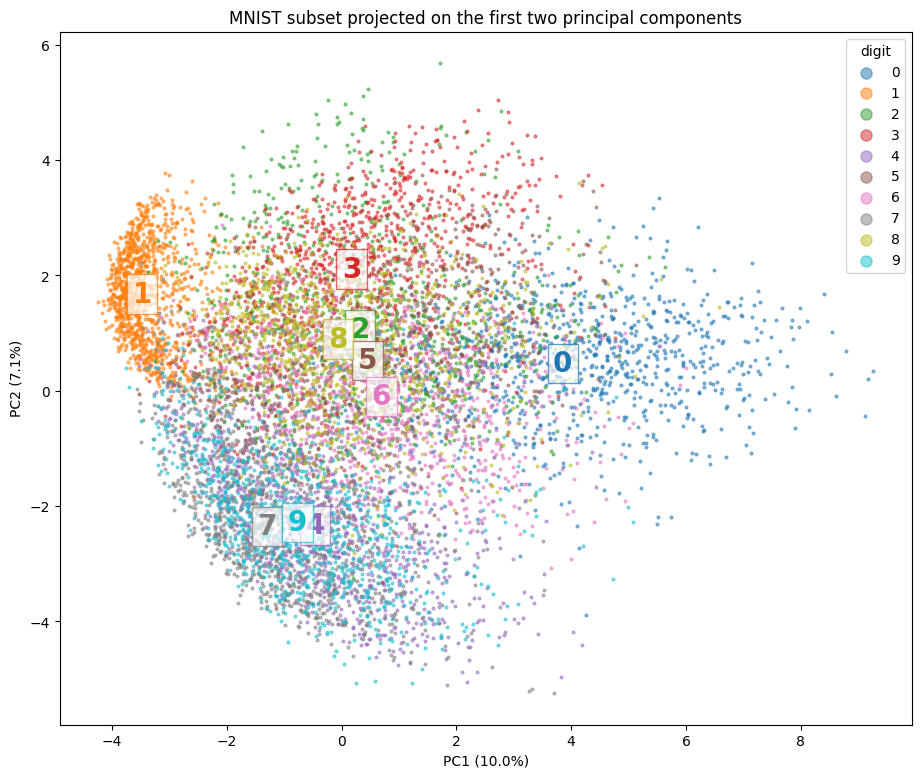

In [9]:
Z = pca.transform(X)[:, :2]

fig, ax = plt.subplots(figsize=(11, 9))
cmap = plt.get_cmap("tab10")
for d in range(10):
    m = y == d
    ax.scatter(Z[m, 0], Z[m, 1], s=4, alpha=0.5, color=cmap(d), label=str(d))
# write the digit at the centre of its cloud
for d in range(10):
    cx, cy = np.median(Z[y == d], axis=0)
    ax.text(cx, cy, str(d), fontsize=20, fontweight="bold", ha="center", va="center",
            color=cmap(d), bbox=dict(facecolor="white", alpha=0.7, edgecolor=cmap(d)))
ax.set_xlabel(f"PC1 ({ratio[0]:.1%})"); ax.set_ylabel(f"PC2 ({ratio[1]:.1%})")
ax.set_title("MNIST subset projected on the first two principal components")
ax.legend(markerscale=4, title="digit", loc="upper right")
plt.show()

The plot is very crowded. Small plots per digit make it easier to see where each digit lies and how much the clouds overlap:

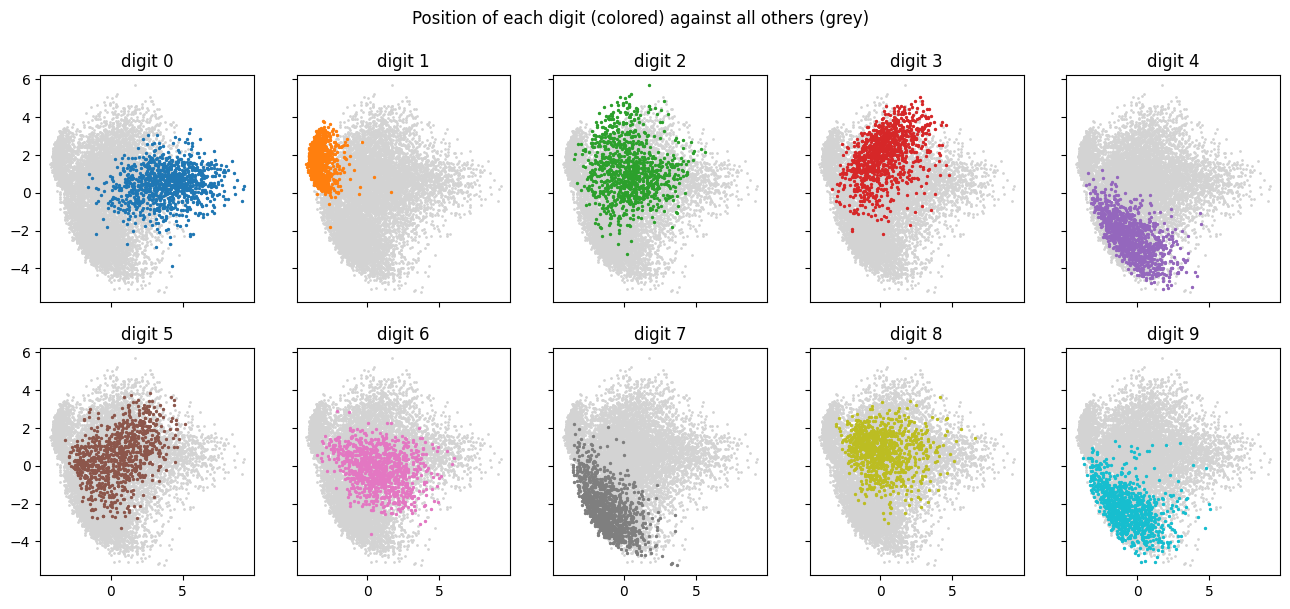

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(16, 6.5), sharex=True, sharey=True)
for d, a in enumerate(axes.ravel()):
    a.scatter(Z[:, 0], Z[:, 1], s=1, color="lightgrey")
    m = y == d
    a.scatter(Z[m, 0], Z[m, 1], s=2, color=cmap(d))
    a.set_title(f"digit {d}")
plt.suptitle("Position of each digit (colored) against all others (grey)")
plt.show()

To put a number on "can the digits be separated?", we train a simple classifier (k-nearest neighbours) on the 2-D PCA data
and compare it with more components. This is only a check of the separability, not part of the PCA itself.

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)
for k in [2, 10, 50, 86]:
    p = PCA(n_components=k).fit(Xtr)                 # fit PCA only on training data
    knn = KNeighborsClassifier(n_neighbors=5).fit(p.transform(Xtr), ytr)
    acc = knn.score(p.transform(Xte), yte)
    print(f"{k:3d} PCs ({np.cumsum(p.explained_variance_ratio_)[-1]:.0%} variance): kNN accuracy = {acc:.1%}")

  2 PCs (17% variance): kNN accuracy = 42.4%


 10 PCs (49% variance): kNN accuracy = 90.1%


 50 PCs (83% variance): kNN accuracy = 95.0%


 86 PCs (90% variance): kNN accuracy = 94.9%


### Can the digits be separated in the reduced space?

**Only partly – mostly not.**
- Some digits form clearly visible regions: **0** (right side, PC1 is large for the "ring" shape) and **1** (far left,
  a very compact cloud – a "1" has little ink and little variation). PC2 separates the group **4 / 7 / 9** (bottom) from
  **2 / 3 / 5 / 8** (top).
- But inside these groups the clouds **overlap almost completely**: **4, 7, 9** lie on top of each other, and **2, 3, 5, 6, 8**
  are mixed in the middle. Even 0 and 1 overlap with their neighbours at the edges.
- A kNN classifier on the 2-D data reaches only about **42 %** accuracy (random guessing = 10 %); with 10 PCs it
  reaches 90 % and with 50 PCs about 95 %.

### Is this result expectable from (b)?

**Yes.** In (b) we saw that PC1 + PC2 explain only **≈ 17 %** of the variance and that about 86 components are needed for 90 %.
When we throw away more than 80 % of the information, it is no surprise that digits that differ only in details (4 / 9, 3 / 5 / 8)
fall on top of each other. In addition, PCA is a **linear** method: it finds the directions of largest variance, not the directions
that best separate the classes, and the "manifold" of handwritten digits is strongly non-linear.

➡ For visualizing MNIST in 2-D, non-linear methods such as **t-SNE** (next part of the lecture) give a much better separation.
PCA is still very useful as a **preprocessing step** (e.g. reduce 784 → 50 dimensions before t-SNE or a classifier).

## Summary

| Question | Answer |
|---|---|
| (a) Data | Images of handwritten digits, rows = images (subset of 10 000), columns = 784 pixel gray values 0 – 255, label 0 – 9. **No standardization**: all variables have the same meaning and range; we only divide by 255. |
| (b) Dimensions | PC1 ≈ 10 %, PC1+PC2 ≈ 17 %. 90 % needs ≈ 86 PCs, 95 % ≈ 151 PCs (out of 784). |
| (c) 2-D plot | Digits 0 and 1 are fairly well separated, but most digits overlap strongly (4/7/9, 2/3/5/6/8). kNN in 2-D: only ≈ 42 % accuracy. Expected, because 2 PCs keep only 17 % of the variance and PCA is linear. |